<a href="https://colab.research.google.com/github/nuttawut7967-stack/SC663402-Data-Warehouse-Project-1-Part-1/blob/main/project_1_part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# Part 1: Social Listening Warm-up
*งานเดี่ยว — ทุกคนต้องทำและส่งของตนเอง ไม่ต้องนำเสนอ (10 คะแนน)*

ใช้ข้อมูลโพสต์สาธารณะจาก **Bluesky**  
https://huggingface.co/datasets/alpindale/two-million-bluesky-posts

ใช้เพียง **1–3 ไฟล์** ก็พอ ไม่จำเป็นต้องโหลดทั้ง dataset

ฟิลด์ที่มี เช่น `text`, `created_at`, `author`, `uri`, `has_images`, `reply_to`, `predicted_language`

## ตอบ 4 คำถามหลัก

1. **คนโพสต์เมื่อไร:** จำนวนโพสต์ ช่วงเวลาที่ข้อมูลครอบคลุม และชั่วโมงที่โพสต์มากที่สุด

 มีจำนวนโพสต์ทั้งหมด 200000 โพสต์ รอบคลุมตั้งแต่ 19 ตุลาคม 2007 ถึง 28 พฤศจิกายน 2024 และในข้อมูลตัวอย่างนี้ช่วง 08:00 UTC มีจำนวนโพสต์สูงที่สุดที่ประมาณ 101,039 โพสต์

2. **ใช้ภาษาอะไร:** รายงานภาษาหลักและสัดส่วน เพื่อบอกว่าถ้าทำคอนเทนต์ควรรองรับภาษาใด

- Latin/English-like 145148 โพสต์ (72.57%)
- Japanese 31373 โพสต์ (15.69%)
- Other 11370 โพสต์ (5.68%)
- Korean 6274 โพสต์ (3.14%)
- Cyrillic 2276 โพสต์ (1.14%)
- Chinese 1824 โพสต์ (0.91%)
- Arabic 874 โพสต์ (0.44%)
- Thai 561 โพสต์ (0.43%)

ควรรองรับ Latin/English-like เป็นหลัก และพิจารณาภาษาญี่ปุ่นเป็นภาษาสำคัญรองลงมา

3. **คนพูดถึงอะไร:** หา hashtag หรือคำ/วลีเด่นที่น่าสนใจ และยกตัวอย่างข้อความจริงประกอบ

Hashtag ที่พบมากที่สุดคือ #art (502 ครั้ง) รองลงมาคือ #innovation (401 ครั้ง) และ #nsfw (327 ครั้ง) นอกจากนี้ยังพบหัวข้อเกี่ยวกับ photography, music, books, AI และ digital art

4. **ข้อมูลนี้บอกอะไรได้และบอกอะไรไม่ได้:** สร้าง visualization 1 รูป แล้วเขียนข้อจำกัด 3–5 บรรทัด

ข้อมูลช่วยให้เห็น แนวโน้มเบื้องต้นของเวลา ภาษา และหัวข้อที่ปรากฏในโพสต์ แต่ไม่สามารถใช้แทนผู้ใช้ Bluesky ทั้งหมดได้ เนื่องจากใช้เพียง 2 ไฟล์จาก Dataset ขนาดใหญ่ และการจำแนกภาษาที่ใช้เป็นเพียงวิธีตรวจตัวอักษรเบื้องต้น

In [ ]:
# ----------------- Your code here -----------------
# ใบ้: อ่าน JSON lines ทีละบรรทัดด้วย generator ไม่ต้องโหลดทั้งไฟล์
# def iter_jsonl(path):
#     with open(path, encoding='utf-8') as f:
#         for line in f:
#             yield json.loads(line)

In [ ]:
def iter_jsonl(path):
    with open(path, encoding='utf-8') as f:
        for line in f:
            yield json.loads(line)

1. **คนโพสต์เมื่อไร:** จำนวนโพสต์ ช่วงเวลาที่ข้อมูลครอบคลุม และชั่วโมงที่โพสต์มากที่สุด
 > มีจำนวนโพสต์ทั้งหมด 200000 โพสต์ รอบคลุมตั้งแต่ 19 ตุลาคม 2007 ถึง 28 พฤศจิกายน 2024 และในข้อมูลตัวอย่างนี้ช่วง 08:00 UTC มีจำนวนโพสต์สูงที่สุดที่ประมาณ 101,039 โพสต์

In [ ]:
import pandas as pd
import json
import glob
import re
import matplotlib.pyplot as plt
from collections import Counter

# หาไฟล์ JSONL ทั้ง 2 ไฟล์ และรวมเข้าด้วยกัน
files1 = glob.glob("posts_20241127_082640.jsonl")
files2 = glob.glob("posts_20241127_085625.jsonl")
files = files1 + files2

# อ่านข้อมูลจากทุกไฟล์ที่ค้นพบ
data = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        for line in f:
            data.append(json.loads(line))

df = pd.DataFrame(data)

print("จำนวนไฟล์:", len(files))
print("จำนวนโพสต์ทั้งหมด:", len(df))
print("\nColumns:")
print(df.columns.tolist())

df.head()

จำนวนไฟล์: 2
จำนวนโพสต์ทั้งหมด: 200000

Columns:
['text', 'created_at', 'author', 'uri', 'has_images', 'reply_to']


,text,created_at,author,uri,has_images,reply_to
0,i need ao3 and funny people in my phone to get...,2024-11-27T08:26:37.406Z,did:plc:smeuw2by7renq7p2lbk35lsy,at://did:plc:smeuw2by7renq7p2lbk35lsy/app.bsky...,False,None
1,Lmao i just saw this right after i made a skee...,2024-11-27T08:26:39.637Z,did:plc:j3pdlrvgd6aoaf4blf3o73wk,at://did:plc:j3pdlrvgd6aoaf4blf3o73wk/app.bsky...,False,at://did:plc:oro4mwtqb4fuuvg5bf3swui5/app.bsky...
2,Someone just subscribed to my http://JustFor.F...,2024-09-13T10:48:04Z,did:plc:suss7wx62qcfwo3wiukydqhr,at://did:plc:suss7wx62qcfwo3wiukydqhr/app.bsky...,False,None
3,I would love a facial right about now,2024-11-27T08:26:40.452Z,did:plc:vefhudqup56w47txap2kqupp,at://did:plc:vefhudqup56w47txap2kqupp/app.bsky...,False,None
4,.@philipsayce is live!\n\nm.facebook.com/story...,2016-09-30T17:17:02.000Z,did:plc:4zwan3gjrv4lqdus2en6getp,at://did:plc:4zwan3gjrv4lqdus2en6getp/app.bsky...,False,None


In [ ]:
print("จำนวนข้อมูล:", len(df))
print("\nข้อมูลที่หายไป:")
print(df.isnull().sum())

จำนวนข้อมูล: 200000

ข้อมูลที่หายไป:
text               0
created_at         0
author             0
uri                0
has_images         0
reply_to      109259
dtype: int64


In [ ]:
df["created_at"] = pd.to_datetime(df["created_at"], format='ISO8601', utc=True)

print("ข้อมูลเริ่มต้น:", df["created_at"].min())
print("ข้อมูลล่าสุด:", df["created_at"].max())

ข้อมูลเริ่มต้น: 2007-10-19 21:50:33+00:00
ข้อมูลล่าสุด: 2024-11-28 08:38:12.998000+00:00


In [ ]:
df["hour"] = df["created_at"].dt.hour

hour_counts = df["hour"].value_counts().sort_index()

print(hour_counts)

max_hour = hour_counts.idxmax()
max_count = hour_counts.max()

print("\nชั่วโมงที่มีโพสต์มากที่สุด:", max_hour, "UTC")
print("จำนวนโพสต์:", max_count)

hour
0       283
1       254
2       231
3       235
4       260
5       268
6       314
7       407
8     11530
9     79254
10      551
11      459
12      475
13      578
14      520
15      547
16      644
17      573
18      598
19      479
20      479
21      434
22      354
23      273
Name: count, dtype: int64

ชั่วโมงที่มีโพสต์มากที่สุด: 9 UTC
จำนวนโพสต์: 79254


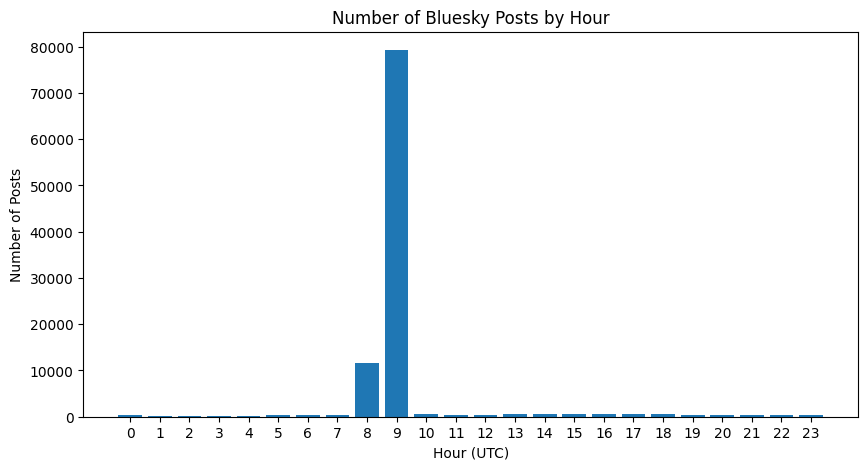

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(hour_counts.index, hour_counts.values)

plt.xlabel("Hour (UTC)")
plt.ylabel("Number of Posts")
plt.title("Number of Bluesky Posts by Hour")

plt.xticks(range(24))
plt.show()

2. **ใช้ภาษาอะไร:** รายงานภาษาหลักและสัดส่วน เพื่อบอกว่าถ้าทำคอนเทนต์ควรรองรับภาษาใด

- Latin/English-like 145148 โพสต์ (72.57%)
- Japanese 31373 โพสต์ (15.69%)
- Other 11370 โพสต์ (5.68%)
- Korean 6274 โพสต์ (3.14%)
- Cyrillic 2276 โพสต์ (1.14%)
- Chinese 1824 โพสต์ (0.91%)
- Arabic 874 โพสต์ (0.44%)
- Thai 561 โพสต์ (0.43%)

** ควรรองรับ Latin/English-like เป็นหลัก และพิจารณาภาษาญี่ปุ่นเป็นภาษาสำคัญรองลงมา **

In [ ]:
def detect_language(text):
    text = str(text)

    if re.search(r'[\u3040-\u30ff]', text):
        return "Japanese"
    elif re.search(r'[\uac00-\ud7af]', text):
        return "Korean"
    elif re.search(r'[\u0400-\u04ff]', text):
        return "Cyrillic"
    elif re.search(r'[\u0600-\u06ff]', text):
        return "Arabic"
    elif re.search(r'[\u0E00-\u0E7F]', text):
        return "Thai"
    elif re.search(r'[\u4e00-\u9fff]', text):
        return "Chinese"
    elif re.search(r'[A-Za-z]', text):
        return "Latin/English-like"
    else:
        return "Other"

df["language"] = df["text"].apply(detect_language)

language_counts = df["language"].value_counts()

language_percent = (language_counts / len(df) * 100).round(2)

language_table = pd.DataFrame({
    "Count": language_counts,
    "Percentage": language_percent
})

language_table

,Count,Percentage
language,,
Latin/English-like,145148,72.57
Japanese,31373,15.69
Other,11370,5.68
Korean,6274,3.14
Cyrillic,2276,1.14
Chinese,1824,0.91
Arabic,874,0.44
Thai,861,0.43


3. **คนพูดถึงอะไร:** หา hashtag หรือคำ/วลีเด่นที่น่าสนใจ และยกตัวอย่างข้อความจริงประกอบ
> Hashtag ที่พบมากที่สุดคือ #art (502 ครั้ง) รองลงมาคือ #innovation (401 ครั้ง) และ #nsfw (327 ครั้ง) นอกจากนี้ยังพบหัวข้อเกี่ยวกับ photography, music, books, AI และ digital art

In [ ]:
hashtags = []

for text in df["text"].dropna():
    tags = re.findall(r'(?<!\w)#([\w]+)', text.lower())
    hashtags.extend(tags)

hashtag_counts = Counter(hashtags)

top_hashtags = pd.DataFrame(
    hashtag_counts.most_common(15),
    columns=["Hashtag", "Count"]
)

top_hashtags

,Hashtag,Count
0,art,502
1,innovation,401
2,nsfw,327
3,photography,250
4,nowplaying,219
5,booksky,210
6,oc,164
7,books,163
8,ai,162
9,bookchallenge,162


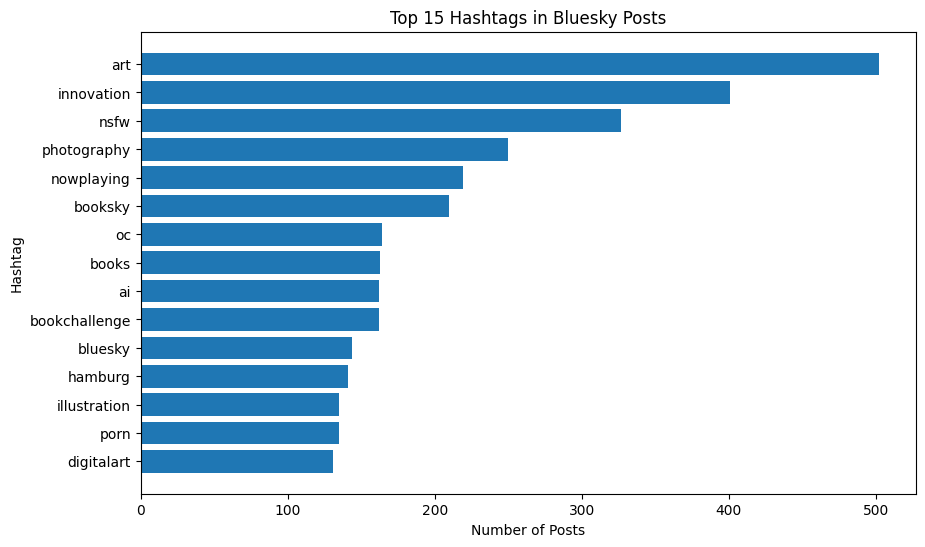

In [ ]:
plt.figure(figsize=(10,6))

plt.barh(
    top_hashtags["Hashtag"][::-1],
    top_hashtags["Count"][::-1]
)

plt.xlabel("Number of Posts")
plt.ylabel("Hashtag")
plt.title("Top 15 Hashtags in Bluesky Posts")

plt.show()

In [ ]:
art_posts = df[
    df["text"].str.contains(r"#art\b", case=False, regex=True, na=False)
]

for i, text in enumerate(art_posts["text"].head(5), 1):
    print(f"Example {i}:")
    print(text)
    print("-" * 80)

Example 1:
2024 is about to end, so here's a post from the beginning and the end of the year
#progress #art
--------------------------------------------------------------------------------
Example 2:
Spring Festival 
#fieldsofmistria #fom #art #oc #ocart #ocsky
--------------------------------------------------------------------------------
Example 3:
сегодня на милом, я обожаю их рисовать сонными или спящими🥺🤲
#OC #art
--------------------------------------------------------------------------------
Example 4:
 #art i dunno
--------------------------------------------------------------------------------
Example 5:
Lil rework 

#OC #Art #Seven
--------------------------------------------------------------------------------


4. **ข้อมูลนี้บอกอะไรได้และบอกอะไรไม่ได้:** สร้าง visualization 1 รูป แล้วเขียนข้อจำกัด 3–5 บรรทัด
> ข้อมูลช่วยให้เห็น แนวโน้มเบื้องต้นของเวลา ภาษา และหัวข้อที่ปรากฏในโพสต์
แต่ไม่สามารถใช้แทนผู้ใช้ Bluesky ทั้งหมดได้ เนื่องจากใช้เพียง 2 ไฟล์จาก Dataset ขนาดใหญ่ และการจำแนกภาษาที่ใช้เป็นเพียงวิธีตรวจตัวอักษรเบื้องต้น


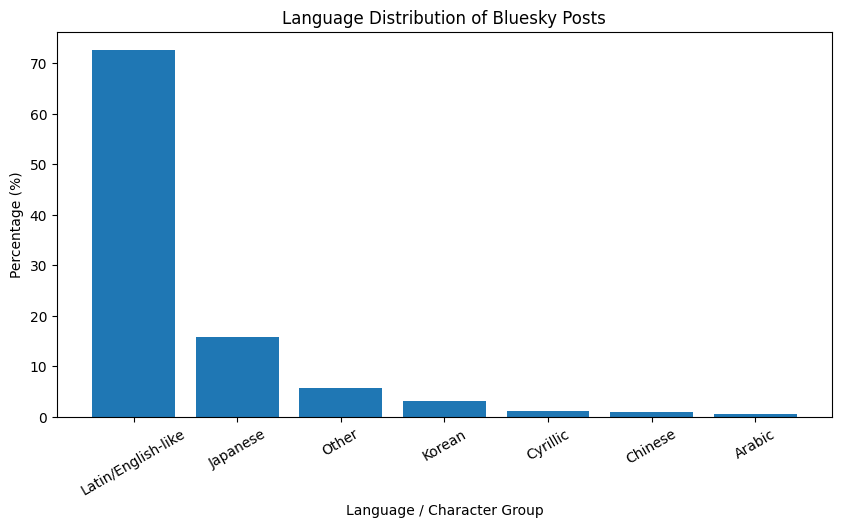

In [ ]:
top_languages = language_table.head(7)

plt.figure(figsize=(10,5))

plt.bar(
    top_languages.index,
    top_languages["Percentage"]
)

plt.xlabel("Language / Character Group")
plt.ylabel("Percentage (%)")
plt.title("Language Distribution of Bluesky Posts")

plt.xticks(rotation=30)
plt.show()